# Week 2 EDA: Players and Teams (Ousmane)

**Question:** how much does a shot's chance of going in depend on *who* is shooting and *who* they're playing against?

**Data:** `train_with_player_bio.csv` (2021–22 to 2024–25). **Never load the test file here.**

**How to run:** put this notebook and `train_with_player_bio.csv` in the same folder, open the folder in VS Code, then click **Run All** (or run each cell with Shift + Enter). Every chart is also saved as a PNG in a `charts/` folder for the slides.

In [37]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

DATA_FILE = "train_with_player_bio.csv"   # Ruifeng's training file (put it in the same folder as this notebook)
os.makedirs("charts", exist_ok=True)

# Chart style: thin marks, light grid, dark text
BLUE, ORANGE = "#2a78d6", "#eb6834"      # series colors
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10, "axes.axisbelow": True,
})
# Diverging colors: orange = below league, gray = average, blue = above league
DIVERGE = LinearSegmentedColormap.from_list("div", ["#c2491a", "#f3c7b2", "#f2f1ee", "#a9c9f2", "#1b5fae"])

def save(fig, name):
    fig.savefig(f"charts/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def make_pct(df, by, min_shots=1):
    """Make % and number of shots for each group. Drops groups with fewer than min_shots."""
    out = df.groupby(by, observed=True)["MADE"].agg(make_pct="mean", shots="size").reset_index()
    out["make_pct"] *= 100
    return out[out["shots"] >= min_shots]

In [38]:
train = pd.read_csv(DATA_FILE, dtype={"GAME_ID": str}, low_memory=False)

# Small prep so Ruifeng's file has the columns this notebook uses
if "PLAYER_HEIGHT_INCHES" in train.columns:
    train = train.rename(columns={"PLAYER_HEIGHT_INCHES": "HEIGHT_IN", "PLAYER_WEIGHT": "WEIGHT_LB"})
if "TEAM" not in train.columns:
    # A team's own abbreviation appears in every one of its games -> most common one is theirs
    both = pd.concat([train[["TEAM_NAME", "HOME_TEAM"]].rename(columns={"HOME_TEAM": "ABB"}),
                      train[["TEAM_NAME", "AWAY_TEAM"]].rename(columns={"AWAY_TEAM": "ABB"})])
    abb = both.groupby("TEAM_NAME")["ABB"].agg(lambda s: s.value_counts().idxmax())
    train["TEAM"] = train["TEAM_NAME"].map(abb)
    train["OPPONENT"] = train["AWAY_TEAM"].where(train["HOME_TEAM"] == train["TEAM"], train["HOME_TEAM"])
# Undrafted players have a missing (or 0) draft pick -> treat as pick 61
train["DRAFT_NUMBER"] = train["DRAFT_NUMBER"].fillna(0).replace(0, 61)
# One name per player ID (a few players appear under two spellings)
train["PLAYER_NAME"] = train["PLAYER_ID"].map(train.sort_values("SEASON").groupby("PLAYER_ID")["PLAYER_NAME"].last())

# Safety check: this must be TRAINING data only
assert "2025-26" not in set(train["SEASON"]), "This is the test file! Load the training file"

LEAGUE = train["MADE"].mean() * 100
print(f"{len(train):,} shots | {train['PLAYER_ID'].nunique()} players | "
      f"{train['TEAM'].nunique()} teams | seasons {sorted(train['SEASON'].unique())}")
print(f"League make %: {LEAGUE:.1f}%")
train.head()

872,169 shots | 913 players | 30 teams | seasons ['2021-22', '2022-23', '2023-24', '2024-25']
League make %: 47.0%


,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,...,HEIGHT_IN,WEIGHT_LB,AGE,COUNTRY,COLLEGE,DRAFT_YEAR,DRAFT_ROUND,DRAFT_NUMBER,TEAM,OPPONENT
0,2022,2021-22,1610612737,Atlanta Hawks,1628381,John Collins,F,F-C,10-21-2021,0022100014,...,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0,ATL,DAL
1,2022,2021-22,1610612737,Atlanta Hawks,1629631,De'Andre Hunter,F,F-G,10-21-2021,0022100014,...,80.0,221.0,24.0,USA,Virginia,2019.0,1.0,4.0,ATL,DAL
2,2022,2021-22,1610612737,Atlanta Hawks,1629027,Trae Young,G,G,10-21-2021,0022100014,...,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0,ATL,DAL
3,2022,2021-22,1610612737,Atlanta Hawks,1628381,John Collins,F,F-C,10-21-2021,0022100014,...,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0,ATL,DAL
4,2022,2021-22,1610612737,Atlanta Hawks,203992,Bogdan Bogdanović,G,G,10-21-2021,0022100014,...,78.0,225.0,29.0,Serbia,NaN,2014.0,1.0,27.0,ATL,DAL


## 1. How many shots does each player take?

How many shots each player took in the training seasons.

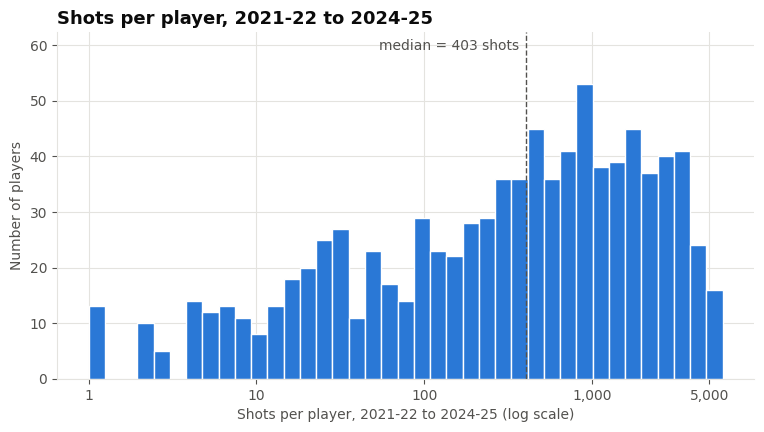

Players with fewer than  10 shots:   78 (9% of players)
Players with fewer than  50 shots:  211 (23% of players)
Players with fewer than 100 shots:  269 (29% of players)
Players with fewer than 500 shots:  499 (55% of players)

The top 100 players take 44% of all shots.


,PLAYER_ID,PLAYER_NAME,shots
248,1628369,Jayson Tatum,6014
469,1630162,Anthony Edwards,5956
312,1628983,Shai Gilgeous-Alexander,5576
344,1629029,Luka Dončić,5529
38,201942,DeMar DeRozan,5501
342,1629027,Trae Young,5318
180,1626164,Devin Booker,5213
124,203507,Giannis Antetokounmpo,5211
254,1628378,Donovan Mitchell,5187
247,1628368,De'Aaron Fox,5135


In [39]:
per_player = train.groupby(["PLAYER_ID", "PLAYER_NAME"]).size().rename("shots").reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(0, np.log10(per_player["shots"].max()), 40)
ax.hist(per_player["shots"], bins=bins, color=BLUE, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 1000, 5000], ["1", "10", "100", "1,000", "5,000"])
ax.minorticks_off()
ax.set_xlabel("Shots per player, 2021-22 to 2024-25 (log scale)")
ax.set_ylabel("Number of players")
ax.set_title("Shots per player, 2021-22 to 2024-25")
med = per_player["shots"].median()
ax.axvline(med, color=INK2, linestyle="--", linewidth=1)
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)
ax.text(med / 1.1, ax.get_ylim()[1] * 0.95, f"median = {med:.0f} shots", color=INK2, ha="right")
save(fig, "1_shots_per_player")

for cut in [10, 50, 100, 500]:
    n = (per_player["shots"] < cut).sum()
    print(f"Players with fewer than {cut:>3} shots: {n:>4} ({n / len(per_player):.0%} of players)")

top = per_player.nlargest(10, "shots")
share = per_player.nlargest(100, "shots")["shots"].sum() / len(train)
print(f"\nThe top 100 players take {share:.0%} of all shots.")
top

Findinds: Looking at this histogram we see how shot volume is very uneven. The top 100 players take 44% of ll shots while 23% of players have fewer than 50 shots. For those players their are not enough shots to get a reliable shooting percentage. Though this helps with our future features  isntead of using raw percentage we could blend each players shooting percentage with the nba average. That way players with fewwer shots are pulled closer to the average.

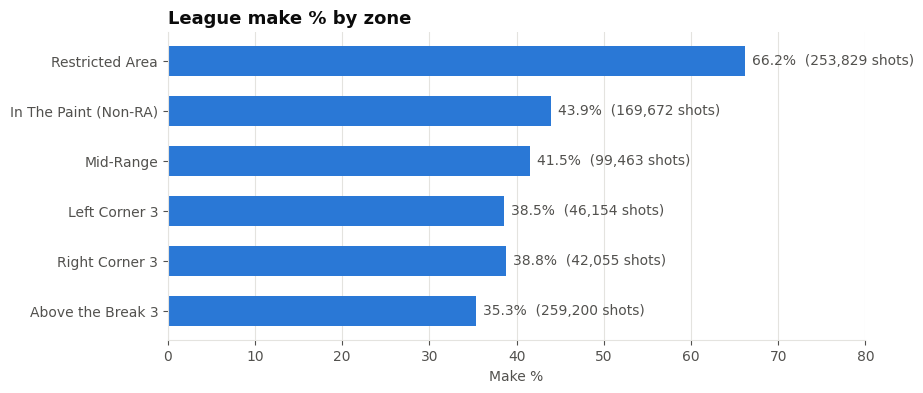

,make_pct,shots
BASIC_ZONE,,
Restricted Area,66.156743,253829
In The Paint (Non-RA),43.927696,169672
Mid-Range,41.536049,99463
Left Corner 3,38.538372,46154
Right Corner 3,38.792058,42055
Above the Break 3,35.332562,259200


In [40]:
ZONES = ["Restricted Area", "In The Paint (Non-RA)", "Mid-Range",
         "Left Corner 3", "Right Corner 3", "Above the Break 3"]

zone = make_pct(train, "BASIC_ZONE").set_index("BASIC_ZONE").loc[ZONES]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(zone.index[::-1], zone["make_pct"][::-1], color=BLUE, height=0.6)
for y, (v, n) in enumerate(zip(zone["make_pct"][::-1], zone["shots"][::-1])):
    ax.text(v + 0.8, y, f"{v:.1f}%  ({n:,} shots)", va="center", color=INK2)
ax.set_xlim(0, 80)
ax.set_xlabel("Make %")
ax.set_title("League make % by zone")
ax.grid(axis="y", visible=False)
save(fig, "2a_league_make_pct_by_zone")
zone

Findings: Shots at the rim go in about 66.2% and 3 pointers made outisde of corers is at 35.3%. Which is expected since rim shots are most likey to go in. I noticed The farther from the basket the lower the make % we see this pattern from resrticted area- regular threes the shot percentage decreases drastically. But that dosen't rule out the other zones complelty becuase the chart shows us how corner thress go in more often then regualr thress(left cordner and right corner thress at about 38% and regular thress at 35%). Players mostly shoot at the rim or from three point positions. We see this in the chart the common zones are regular threes (259,200) and at the rim(253,829). Which is about 59% of all shots, mid range shooters are very rae st 99,463 shots. But this gives a good model insight, zone is a strong predictor since make % rnages from 35-66% depdneing on the location.shot location might the most important feature

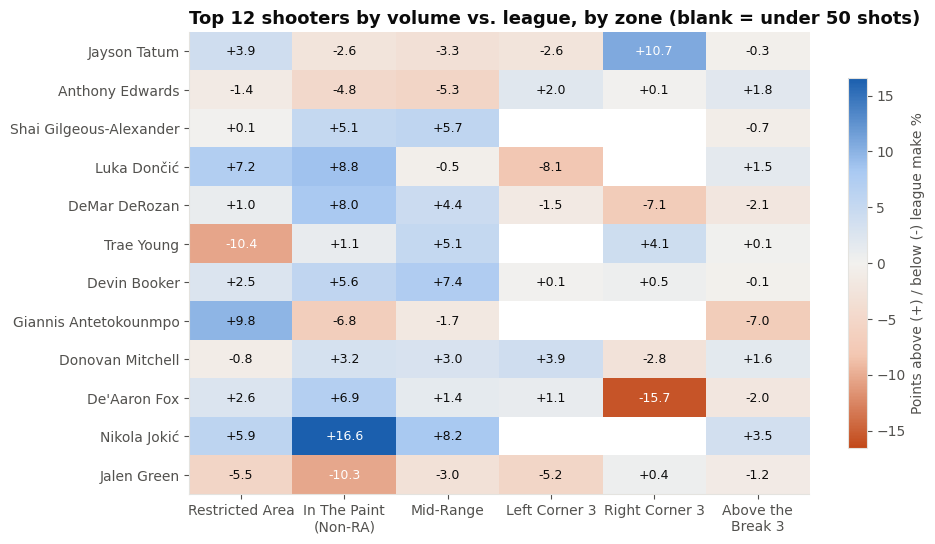

BASIC_ZONE,Restricted Area,In The Paint (Non-RA),Mid-Range,Left Corner 3,Right Corner 3,Above the Break 3
PLAYER_NAME,,,,,,
Jayson Tatum,3.9,-2.6,-3.3,-2.6,10.7,-0.3
Anthony Edwards,-1.4,-4.8,-5.3,2.0,0.1,1.8
Shai Gilgeous-Alexander,0.1,5.1,5.7,NaN,NaN,-0.7
Luka Dončić,7.2,8.8,-0.5,-8.1,NaN,1.5
DeMar DeRozan,1.0,8.0,4.4,-1.5,-7.1,-2.1
Trae Young,-10.4,1.1,5.1,NaN,4.1,0.1
Devin Booker,2.5,5.6,7.4,0.1,0.5,-0.1
Giannis Antetokounmpo,9.8,-6.8,-1.7,NaN,NaN,-7.0
Donovan Mitchell,-0.8,3.2,3.0,3.9,-2.8,1.6


In [41]:
MIN_ZONE_SHOTS = 50
top12 = per_player.nlargest(12, "shots")["PLAYER_ID"]
sub = train[train["PLAYER_ID"].isin(top12)]

p = make_pct(sub, ["PLAYER_NAME", "BASIC_ZONE"])
p.loc[p["shots"] < MIN_ZONE_SHOTS, "make_pct"] = np.nan
grid = p.pivot(index="PLAYER_NAME", columns="BASIC_ZONE", values="make_pct")[ZONES]
diff = grid - zone["make_pct"]                        # points above/below league
order = per_player.set_index("PLAYER_ID").loc[top12, "PLAYER_NAME"]
diff = diff.loc[order]

fig, ax = plt.subplots(figsize=(10, 6))
lim = np.nanmax(np.abs(diff.values))
im = ax.imshow(diff.values, cmap=DIVERGE, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_xticks(range(len(ZONES)), [z.replace(" (Non-RA)", "\n(Non-RA)").replace("Above the Break 3", "Above the\nBreak 3") for z in ZONES])
ax.set_yticks(range(len(diff)), diff.index)
ax.grid(False)
for i in range(diff.shape[0]):
    for j in range(diff.shape[1]):
        v = diff.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > lim * 0.6 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Points above (+) / below (-) league make %", color=INK2)
ax.set_title("Top 12 shooters by volume vs. league, by zone (blank = under 50 shots)")
save(fig, "2b_top_players_vs_league_by_zone")
diff.round(1)

Findings: From looking at the heatmap across the league ake % depends heavily on zone. Shots at the rimmgo in66% of the time compared to only 35% for regular three pointers. And the frather from the basket the lower the make %. The map shwos how each player is strong in some zones  and weak in others. Trae young is below 10.4 points t the rimwhich is intresting since hes an elite scoreer.On top of that diffrent players also vary significantly within the same zone. At the rim giannis is 9.8 points above the league  while young i 10.4 points below and on the right corner thress tatum is 10.7 bove while Deaaron fox is 15.7 below.  We can see hiw player skills depend on the zone one overall shooying  percentage per player isnt enoughso our plyer shooting feature should be calculated by zone

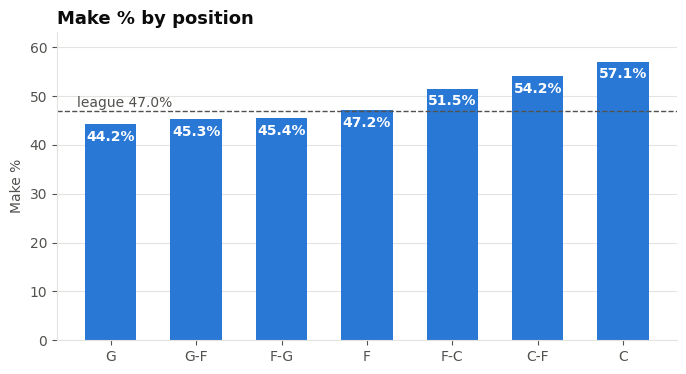

Share of each position's shots by zone (%):


BASIC_ZONE,Restricted Area,In The Paint (Non-RA),Mid-Range,Left Corner 3,Right Corner 3,Above the Break 3
POSITION,,,,,,
G,22.3,18.8,12.6,5.4,4.6,36.0
G-F,24.1,17.6,14.7,6.8,6.4,30.2
F-G,28.8,19.2,10.2,5.6,5.8,30.3
F,30.9,18.1,10.7,6.6,6.1,27.3
F-C,40.1,20.4,8.3,3.3,3.7,24.0
C-F,41.7,23.9,10.4,2.5,2.5,18.9
C,51.9,27.0,7.1,1.1,1.2,11.6


In [30]:
Does Position matter?

Findings: MAke percnetage rises steadily from guards and centers. Guards make 44.2% of their shots forwards  at 47.2%, forwards/ Centers at 54.2%and centers at 57.1% comapred to the league average 47%. that is a 13 point gap between guards and centers but that doesnt mean that centers are better hooters. Looking at the shot mix chart it shows how 51.9% of center shts are made at the rim comapred tp 22.3% of guards . Also guards make up 36% of shots as regular thress comapared to centers who make about 11.6%. So we cna conclude on how cneters have higher make % probably becuase most of them take close up shots.

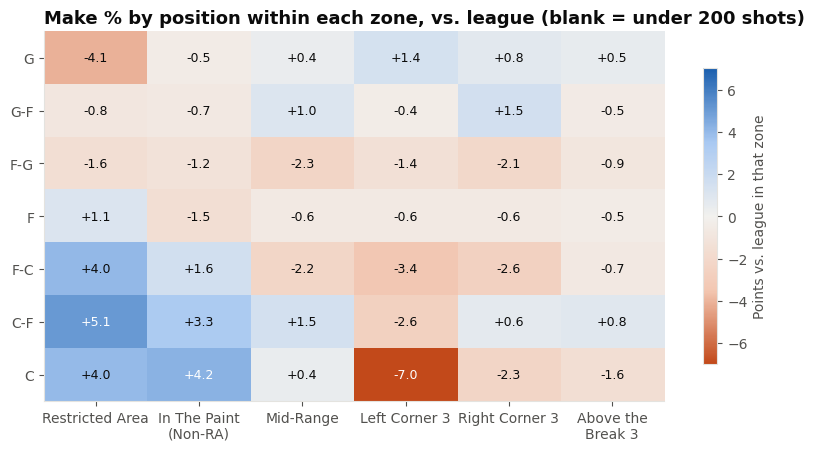

BASIC_ZONE,Restricted Area,In The Paint (Non-RA),Mid-Range,Left Corner 3,Right Corner 3,Above the Break 3
POSITION,,,,,,
G,-4.1,-0.5,0.4,1.4,0.8,0.5
G-F,-0.8,-0.7,1.0,-0.4,1.5,-0.5
F-G,-1.6,-1.2,-2.3,-1.4,-2.1,-0.9
F,1.1,-1.5,-0.6,-0.6,-0.6,-0.5
F-C,4.0,1.6,-2.2,-3.4,-2.6,-0.7
C-F,5.1,3.3,1.5,-2.6,0.6,0.8
C,4.0,4.2,0.4,-7.0,-2.3,-1.6


In [31]:
pz = make_pct(train, ["POSITION", "BASIC_ZONE"], min_shots=200)
pz = pz.pivot(index="POSITION", columns="BASIC_ZONE", values="make_pct").loc[POS, ZONES]
pz_diff = pz - zone["make_pct"]

fig, ax = plt.subplots(figsize=(10, 4.8))
lim = np.nanmax(np.abs(pz_diff.values))
im = ax.imshow(pz_diff.values, cmap=DIVERGE, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_xticks(range(len(ZONES)), [z.replace(" (Non-RA)", "\n(Non-RA)").replace("Above the Break 3", "Above the\nBreak 3") for z in ZONES])
ax.set_yticks(range(len(POS)), POS)
ax.grid(False)
for i in range(pz_diff.shape[0]):
    for j in range(pz_diff.shape[1]):
        v = pz_diff.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(v) > lim * 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8).set_label("Points vs. league in that zone", color=INK2)
ax.set_title("Make % by position within each zone, vs. league (blank = under 200 shots)")
save(fig, "3b_position_vs_league_within_zone")
pz_diff.round(1)

The heatmap hows how when in the same zone the diffrences  are very samll.Cetbers are 8 points better than guards at the rimbut when it comes the 3s the guards are slightly better. So we can see how most the potion gap comes from zone rather than just the players postion alone. Position matters mostly because it tells you where a player shhots from (adds onto to our zone conclusion) but even within the same zone  cneters have higher shots made at the rim comapred to guards who shoot better when they are far from it.

## 4. Do player traits matter? Height, age, draft position

Make % by height (overall, then within two zones), by age, and by draft position.

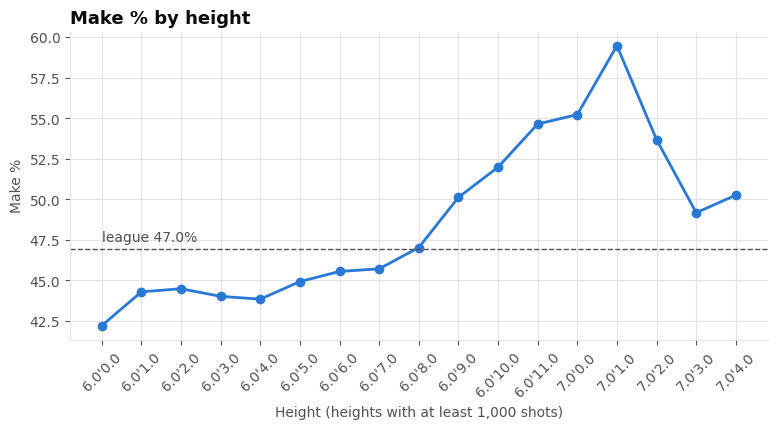

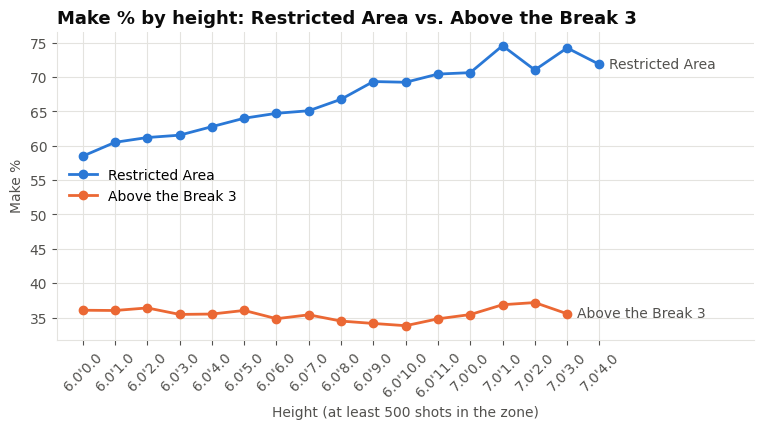

In [32]:
h = make_pct(train, "HEIGHT_IN", min_shots=1000)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h["HEIGHT_IN"], h["make_pct"], color=BLUE, linewidth=2, marker="o", markersize=6)
ax.axhline(LEAGUE, color=INK2, linestyle="--", linewidth=1)
ax.set_xticks(h["HEIGHT_IN"], [f"{i // 12}'{i % 12}" for i in h["HEIGHT_IN"]], rotation=45)
ax.set_xlabel("Height (heights with at least 1,000 shots)")
ax.set_ylabel("Make %")
ax.text(h["HEIGHT_IN"].min(), LEAGUE + 0.3, f"league {LEAGUE:.1f}%", color=INK2, va="bottom")
ax.set_title("Make % by height")
save(fig, "4a_make_pct_by_height")

# Same thing, but within two zones: at the rim vs. threes
two = train[train["BASIC_ZONE"].isin(["Restricted Area", "Above the Break 3"])]
hz = make_pct(two, ["BASIC_ZONE", "HEIGHT_IN"], min_shots=500)

fig, ax = plt.subplots(figsize=(9, 4))
for z, col in [("Restricted Area", BLUE), ("Above the Break 3", ORANGE)]:
    d = hz[hz["BASIC_ZONE"] == z]
    ax.plot(d["HEIGHT_IN"], d["make_pct"], color=col, linewidth=2, marker="o", markersize=6, label=z)
    ax.text(d["HEIGHT_IN"].iloc[-1] + 0.3, d["make_pct"].iloc[-1], z, color=INK2, va="center")
ax.legend(frameon=False, loc="center left")
ax.set_xticks(sorted(hz["HEIGHT_IN"].unique()), [f"{i // 12}'{i % 12}" for i in sorted(hz["HEIGHT_IN"].unique())], rotation=45)
ax.set_xlim(right=ax.get_xlim()[1] + 4)
ax.set_xlabel("Height (at least 500 shots in the zone)")
ax.set_ylabel("Make %")
ax.set_title("Make % by height: Restricted Area vs. Above the Break 3")
save(fig, "4b_height_within_zone")

Height plays big role in make %. Players withheugh 6'9 and taller and make more of their shots hen the league average of 47%, the highest percnyatge is 60  for players who are 7'1, while players who are 6:8 and shorter shoot at or below the nba average. Only  small amount of players are 7:1or taller so the peak is based on a samller group.And the secod chart tells us why.At the rim  make% rises steadily with height from 58.5%for 6 foot players to 70.6%for 7 foot players, but for regular threes make % stays around 35% no matter how tall the player is. So height helps players finish near the basket but not from the outside which shows us again how zone plays a huge part wheter shot goes in or not.

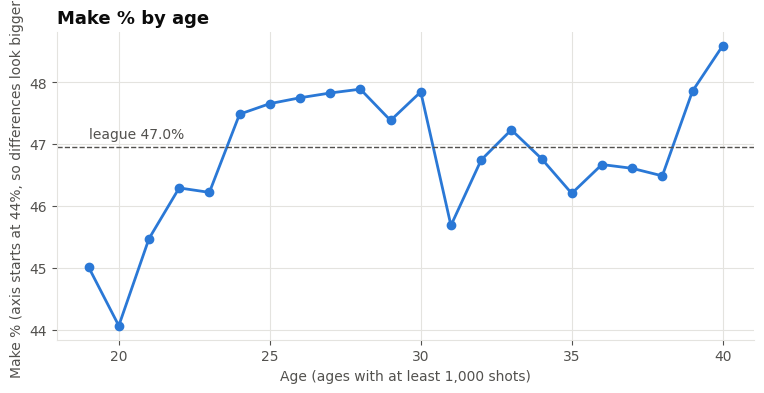

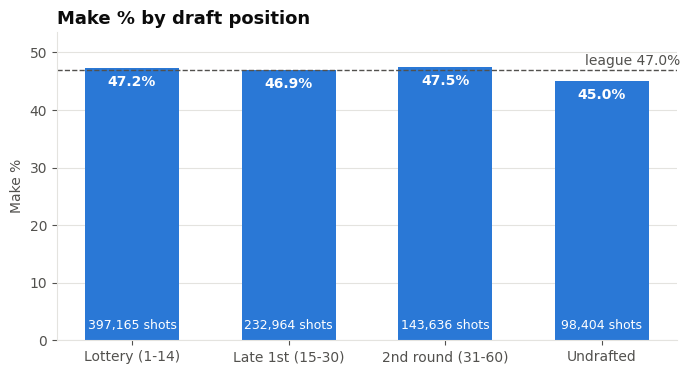

,make_pct,shots
DRAFT_GROUP,,
Lottery (1-14),47.239309,397165
Late 1st (15-30),46.935578,232964
2nd round (31-60),47.504108,143636
Undrafted,45.019511,98404


In [33]:
a = make_pct(train, "AGE", min_shots=1000)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(a["AGE"], a["make_pct"], color=BLUE, linewidth=2, marker="o", markersize=6)
ax.axhline(LEAGUE, color=INK2, linestyle="--", linewidth=1)
ax.text(a["AGE"].min(), LEAGUE + 0.1, f"league {LEAGUE:.1f}%", color=INK2, va="bottom")
ax.set_xlabel("Age (ages with at least 1,000 shots)")
ax.set_ylabel("Make % (axis starts at 44%, so differences look bigger)")
ax.set_title("Make % by age")
save(fig, "4c_make_pct_by_age")

# Draft position: lottery picks vs. later picks vs. undrafted
def draft_group(n):
    if n <= 14: return "Lottery (1-14)"
    if n <= 30: return "Late 1st (15-30)"
    if n <= 60: return "2nd round (31-60)"
    return "Undrafted"
DRAFT = ["Lottery (1-14)", "Late 1st (15-30)", "2nd round (31-60)", "Undrafted"]
train["DRAFT_GROUP"] = train["DRAFT_NUMBER"].map(draft_group)
d = make_pct(train, "DRAFT_GROUP").set_index("DRAFT_GROUP").loc[DRAFT]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(d.index, d["make_pct"], color=BLUE, width=0.6)
ax.axhline(LEAGUE, color=INK2, linestyle="--", linewidth=1)
for x, (v, n) in enumerate(zip(d["make_pct"], d["shots"])):
    ax.text(x, v - 1.2, f"{v:.1f}%", ha="center", va="top", color="white", fontweight="bold")
    ax.text(x, 2, f"{n:,} shots", ha="center", color="white", fontsize=9)
ax.text(len(DRAFT) - 0.5, LEAGUE + 0.8, f"league {LEAGUE:.1f}%", color=INK2, ha="right")
ax.set_ylim(0, d["make_pct"].max() + 6)
ax.set_ylabel("Make %")
ax.set_title("Make % by draft position")
ax.grid(axis="x", visible=False)
save(fig, "4d_make_pct_by_draft")
d

Findings; Younger players under 24 shoot below the league avregae which is about 44-46% and players have the higeht shot perctnage at ages 24 and 30 so about 48%.players aged 39-40 also shoot well but thats mostly players who have been in the legaue for years (lerbon,paul etc). But overall make % chnages  by only a few points when lookingat players age. Also draft positions barely matters : lottery picks, late first round picks  and second round picks all shoot at about 47%. The only expection can be undrafted players  who shoot about 2% lowe. But i honestly dont think that draft postiton will be usueful feature.

## 5. Do some teams or opponents stand out?

Raw make % rewards teams that simply take easier shots. So besides raw make %, this computes **make % above expected**: each shot's expected make % is the league average for its zone, and a team's score is its actual make % minus the average expected for its shots.

- For a **team**, above expected = better shooters.
- For an **opponent** (the defense), *below* expected = better defense.

All of this uses training data only, so it is safe.

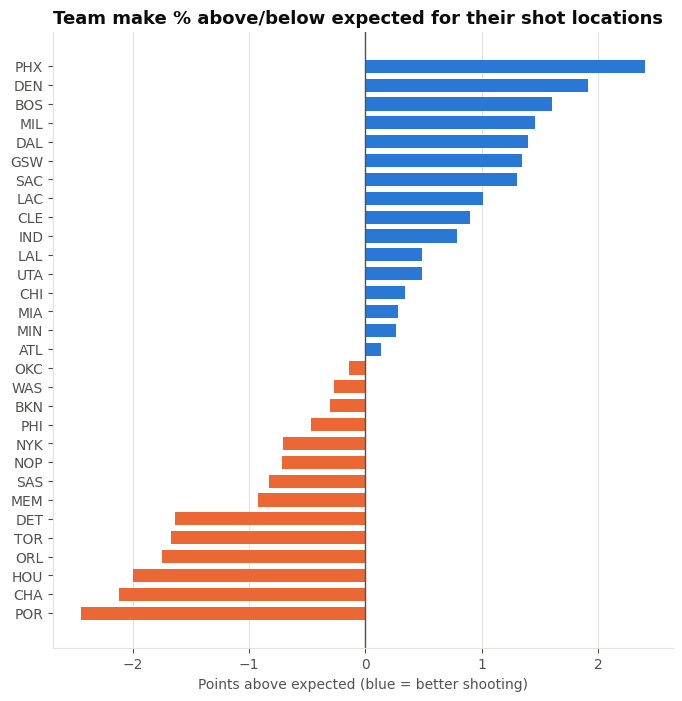

,make_pct,expected,shots,above_expected
TEAM,,,,
POR,45.09,0.48,28897,-2.44
CHA,45.37,0.47,29351,-2.12
HOU,45.67,0.48,29488,-2.00
ORL,45.60,0.47,28312,-1.75
TOR,45.80,0.47,29796,-1.67
DET,45.61,0.47,29006,-1.64
MEM,46.30,0.47,30173,-0.93
SAS,46.49,0.47,29992,-0.83
NOP,46.87,0.48,28925,-0.72


In [34]:
zone_avg = train.groupby("BASIC_ZONE")["MADE"].mean()
train["EXPECTED"] = train["BASIC_ZONE"].map(zone_avg)

def vs_expected(by):
    g = train.groupby(by).agg(make_pct=("MADE", "mean"), expected=("EXPECTED", "mean"), shots=("MADE", "size"))
    g["above_expected"] = (g["make_pct"] - g["expected"]) * 100
    g["make_pct"] *= 100
    return g.sort_values("above_expected")

def diverging_bars(g, title, xlabel, name):
    fig, ax = plt.subplots(figsize=(8, 8))
    colors = [BLUE if v >= 0 else ORANGE for v in g["above_expected"]]
    ax.barh(g.index, g["above_expected"], color=colors, height=0.7)
    ax.axvline(0, color=INK2, linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    save(fig, name)

team = vs_expected("TEAM")
diverging_bars(team, "Team make % above/below expected for their shot locations",
               "Points above expected (blue = better shooting)", "5a_team_vs_expected")
team.round(2)

Findings: Each teams  make % is compared with what we expcted based on the zones and where shots came from. Phonix shot  the ebst at 2.4 points above expected follwoed by denevr and boston for worst percentages portland was at -2.4, follwoed by charlotte and houston. But portland took easier shots then phoenix( expected 47.5% vs 45.7%) but their make perctnage was still low. So we can see how team diffrences are small ranging between +2.4/-2.4 points comapred to the 35%to 66% rnage between zones. So tem matters little comapred to shots zone.

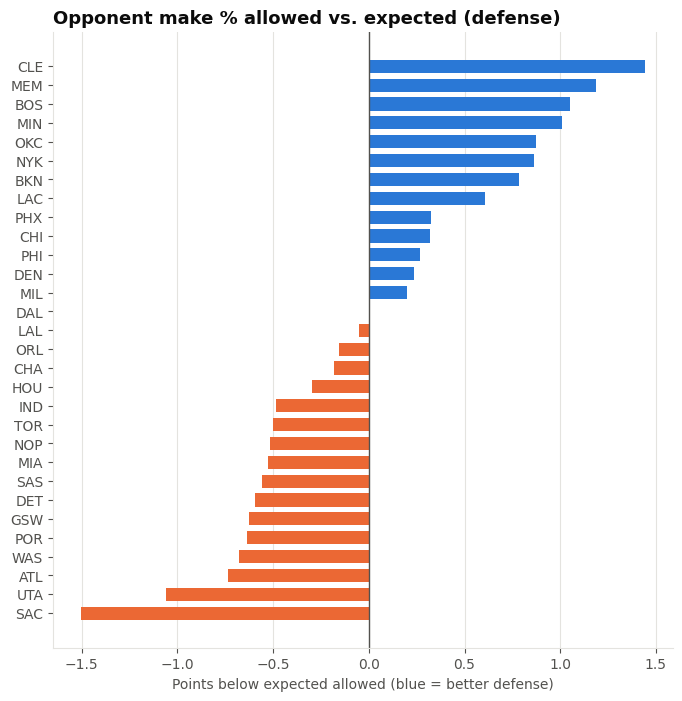

,make_pct,expected,shots,above_expected
OPPONENT,,,,
SAC,48.14,0.47,29027,1.50
UTA,47.32,0.46,29964,1.06
ATL,48.32,0.48,29484,0.74
WAS,47.61,0.47,29878,0.68
POR,48.28,0.48,28563,0.64
GSW,45.96,0.45,29063,0.63
DET,47.84,0.47,28784,0.60
SAS,48.32,0.48,30092,0.56
MIA,46.55,0.46,28026,0.53


In [35]:
opp = vs_expected("OPPONENT").sort_values("above_expected", ascending=False)
# Flip the sign so that, like the team chart, right/blue = good (better defense)
d_plot = opp.assign(above_expected=-opp["above_expected"])
diverging_bars(d_plot, "Opponent make % allowed vs. expected (defense)",
               "Points below expected allowed (blue = better defense)",
               "5b_opponent_defense_vs_expected")
opp.round(2)   # in this table, negative above_expected = better defense

Findings: This chart looks at defense by comparing how well opponets shotagainst each team o what we'd expect based on the zone they shot from. Clevalnd had the best defense holding oppponets 1.4 below exected follwoed by memphis and boston. We also see how sacarmento had the worst % opponets were shotting 1.5 poin ts above  expected followed by utah and and atlnata.Boston is at equal percentage when it comes to defense and shotting. Defense varity between 1.5 teams are pretty small  only about -+1.5 points which is smaller than the team shooting differneces  in the previous chart and much smaller then  the differnece between zones.Overall opponet defnese as samll but real effect and could be a useful feature.

In [ ]:
print("KEY NUMBERS (for reference)")
print(f"- League make %: {LEAGUE:.1f}%")
for cut in [50, 100]:
      
    n = (per_player['shots'] < cut).sum()
    print(f"- Players with < {cut} shots: {n} of {len(per_player)} ({n / len(per_player):.0%})")
print(f"- Top 100 players take {share:.0%} of all shots")
print(f"- Zone make % ranges from {zone['make_pct'].min():.1f}% ({zone['make_pct'].idxmin()}) "
      f"to {zone['make_pct'].max():.1f}% ({zone['make_pct'].idxmax()})")
print(f"- Position make %: {pos['make_pct'].min():.1f}% ({pos['make_pct'].idxmin()}) "
      f"to {pos['make_pct'].max():.1f}% ({pos['make_pct'].idxmax()})")
print(f"- Best shooting team vs expected: {team.index[-1]} ({team['above_expected'].iloc[-1]:+.2f} pts); "
      f"worst: {team.index[0]} ({team['above_expected'].iloc[0]:+.2f} pts)")
print(f"- Toughest defense: {opp.index[-1]} ({opp['above_expected'].iloc[-1]:+.2f} pts allowed); "
      f"weakest: {opp.index[0]} ({opp['above_expected'].iloc[0]:+.2f} pts)")
print(f"\nCharts saved in: {os.path.abspath('charts')}")

KEY NUMBERS (for reference)
- League make %: 47.0%
- Players with < 50 shots: 211 of 913 (23%)
- Players with < 100 shots: 269 of 913 (29%)
- Top 100 players take 44% of all shots
- Zone make % ranges from 35.3% (Above the Break 3) to 66.2% (Restricted Area)
- Position make %: 44.2% (G) to 57.1% (C)
- Best shooting team vs expected: PHX (+2.40 pts); worst: POR (-2.44 pts)
- Toughest defense: CLE (-1.44 pts allowed); weakest: SAC (+1.50 pts)

Charts saved in: /Users/ousmane.local/Downloads/nbafinalproject/charts
